# 02 - Análisis exploratorio
Comportamiento de los precios de las materias primas (X, Y, Z) y de los equipos en el tiempo, y primeras pistas de su relación.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PROCESSED = Path("../data/processed")

historico = pd.read_csv(
    DATA_PROCESSED / "historico_equipos_limpio.csv",
    parse_dates=["Date"]
)
historico.info()

<class 'pandas.DataFrame'>
RangeIndex: 3530 entries, 0 to 3529
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           3530 non-null   datetime64[us]
 1   Price_X        3530 non-null   float64       
 2   Price_Y        3530 non-null   float64       
 3   Price_Z        3530 non-null   float64       
 4   Price_Equipo1  3530 non-null   float64       
 5   Price_Equipo2  3530 non-null   float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 165.6 KB


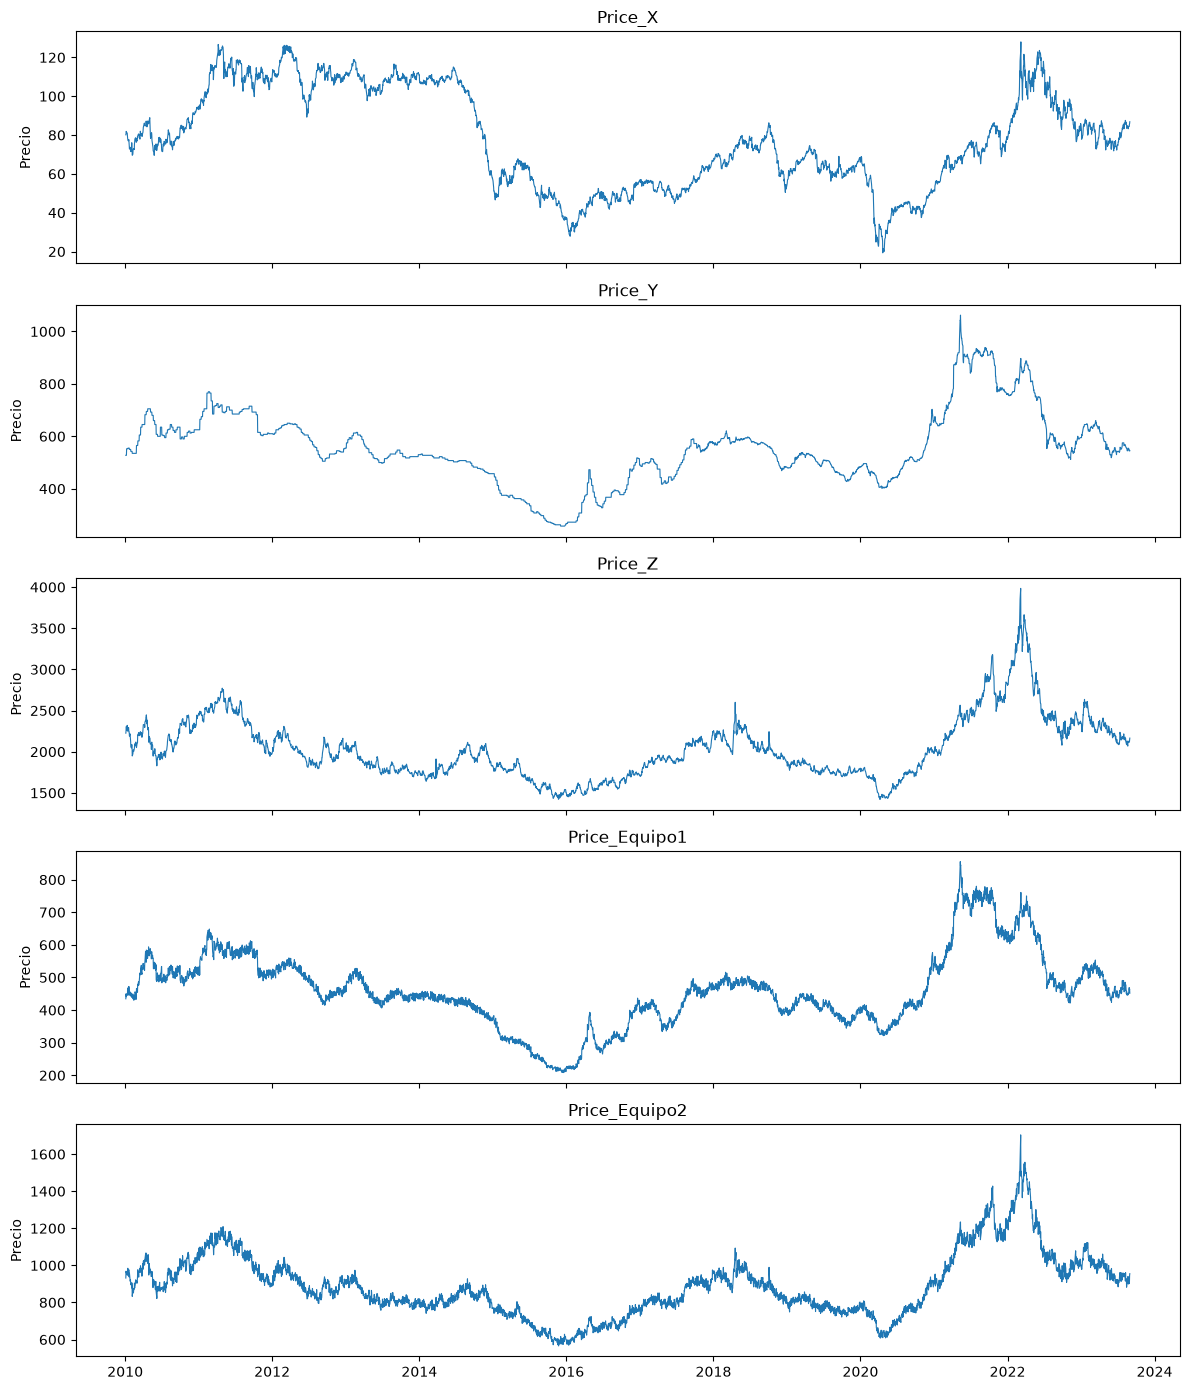

In [2]:
columnas = ["Price_X", "Price_Y", "Price_Z", "Price_Equipo1", "Price_Equipo2"]

fig, axes = plt.subplots(len(columnas), 1, figsize=(12, 14), sharex=True)

for ax, columna in zip(axes, columnas):
    ax.plot(historico["Date"], historico[columna], linewidth=0.8)
    ax.set_title(columna)
    ax.set_ylabel("Precio")

plt.tight_layout()
plt.savefig("../reports/figures/01_series_en_el_tiempo.png", dpi=150)
plt.show()

## Conclusiones del análisis exploratorio

1. El precio de Z y el precio del Equipo 2 tienen un comportamiento similar, tanto en el alza como en la baja de sus precios a lo largo del tiempo.
2. El precio de Y y el precio del Equipo 1 tienen la relación más fuerte: su comportamiento da el efecto de que fueran casi la misma serie a lo largo del tiempo.
3. Entre 2014 y 2016 se evidencia que todos los precios tienden a bajar, pero la mayor caída fue la del precio de X, cerca del 55%.
4. Hipótesis por validar: la baja en este periodo puede tener relación con la caída del precio del petróleo a nivel mundial.

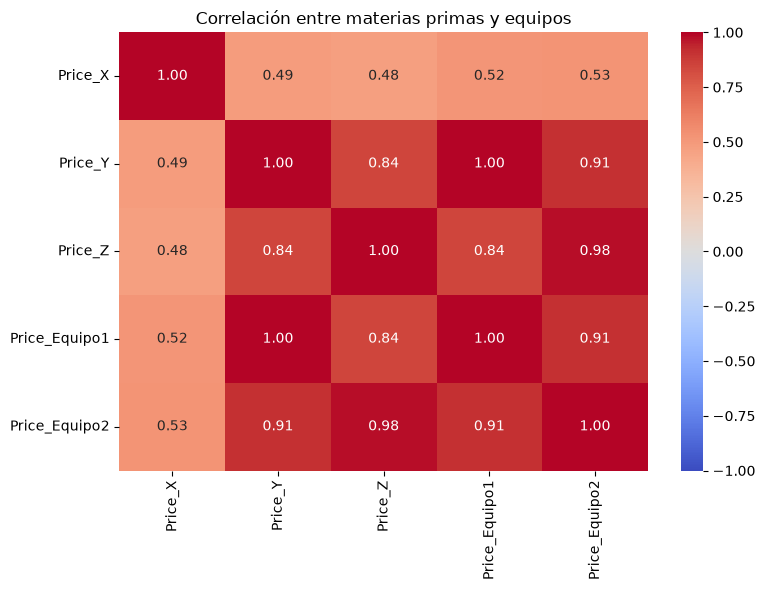

In [3]:
correlacion = historico.drop(columns="Date").corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre materias primas y equipos")
plt.tight_layout()
plt.savefig("../reports/figures/02_matriz_correlacion.png", dpi=150)
plt.show()

## Conclusiones del análisis exploratorio (matriz de correlación)

1. Con esta gráfica se logran ver de una manera más sólida las relaciones expuestas anteriormente. Por ejemplo, entre el precio de Y y el precio del Equipo 1 la correlación es de 0,997 (casi 1), lo que demuestra que ambas se comportan casi como una sola serie.
2. Pasa algo similar con el precio de Z y el precio del Equipo 2, cuya correlación es de 0,98.
3. Sin embargo, el precio de Y y el precio de Z también se parecen entre sí (correlación de 0,84). Por eso, la correlación sola no permite concluir qué materia prima explica cada equipo, y es necesario un modelo que separe el efecto de cada una.

In [4]:
historico.drop(columns="Date").describe().round(2)

,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
count,3530.00,3530.00,3530.00,3530.00,3530.00
mean,78.09,555.53,2037.43,460.04,889.98
std,25.19,138.49,373.14,113.68,170.04
min,19.33,257.50,1421.50,208.34,566.00
25%,57.05,482.50,1767.25,398.23,777.70
50%,75.40,541.62,1974.75,451.25,869.78
75%,104.58,620.00,2235.94,515.61,979.12
max,127.98,1062.37,3984.00,855.32,1703.96


In [5]:
(historico.drop(columns="Date").std() / historico.drop(columns="Date").mean() * 100).round(1)

Price_X          32.3
Price_Y          24.9
Price_Z          18.3
Price_Equipo1    24.7
Price_Equipo2    19.1
dtype: float64

## Estadísticas descriptivas

1. El precio promedio del Equipo 1 es de 460,04 y el del Equipo 2 es de 889,98, casi el doble del Equipo 1.
2. La serie más variable es el precio de X, con un coeficiente de variación de 32,3%, y la más estable es el precio de Z, con 18,3%.
3. Se usa el coeficiente de variación en lugar del std porque el std se mide en pesos, y las series más caras parecen más variables solo por su precio. Al dividir entre el promedio, todas quedan en porcentaje y se pueden comparar.
4. El Equipo 1 varía casi igual que el precio de Y y el Equipo 2 casi igual que el precio de Z, lo que confirma los resultados de la regresión.

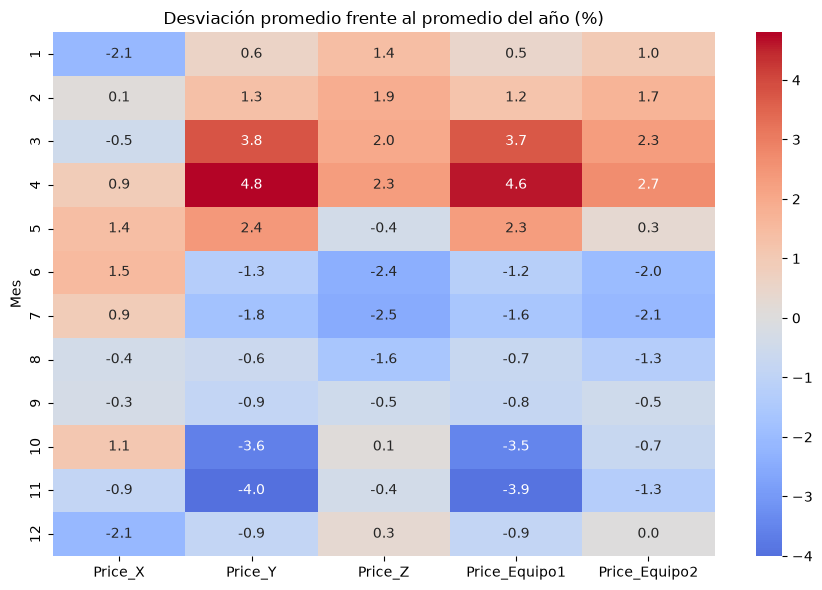

In [6]:
precios = historico[columnas]
promedio_anual = precios.groupby(historico["Date"].dt.year).transform("mean")

desviacion = (precios / promedio_anual - 1) * 100
estacionalidad = desviacion.groupby(historico["Date"].dt.month).mean().round(1)

plt.figure(figsize=(9, 6))
sns.heatmap(estacionalidad, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Desviación promedio frente al promedio del año (%)")
plt.ylabel("Mes")
plt.tight_layout()
plt.savefig("../reports/figures/04_estacionalidad_mensual.png", dpi=150)
plt.show()

## Estacionalidad

1. El precio de Y y el precio del Equipo 1 muestran la estacionalidad más marcada: suelen subir cerca de 4,7% en abril y bajar cerca de 4% en octubre y noviembre, frente al promedio del año.
2. El precio de Z y el del Equipo 2 tienen un patrón más suave, de aproximadamente ±2,5%, y el precio de X no muestra un patrón claro.
3. Como el Equipo 1 depende en un 80% de Y, hereda su estacionalidad. La proyección debe tener en cuenta este patrón.